# Movie Review Mood Checker: BERT + GPU Data Science
**One mini project that combines two NVIDIA DLI courses:**

| Course | What I use from it |
| --- | --- |
| Building Transformer-Based NLP Applications | A BERT-family model (DistilBERT) reads 50,000 movie reviews and labels each one Positive or Negative |
| Fundamentals of Accelerated Data Science | cuDF (GPU pandas) analyses the results, and I time it against normal pandas |

**Story:** *BERT reads 50,000 reviews, and the GPU analyses them in seconds.*

**How to run:** Google Colab -> Runtime -> Change runtime type -> **T4 GPU** -> Runtime -> **Run all** (about 5-8 minutes).

## Step 0: Setup

In [1]:
!pip -q install transformers datasets scikit-learn

import torch, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    import cudf
except ImportError:
    !pip -q install --extra-index-url=https://pypi.nvidia.com cudf-cu12
    import cudf

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - set runtime to T4 GPU")
print("cuDF version:", cudf.__version__)
device = "cuda"

GPU: Tesla T4
cuDF version: 26.06.00


## Step 1: Load 50,000 movie reviews
The **IMDB** dataset: 50,000 reviews, each already labelled positive (1) or negative (0) by humans. I keep those labels to check how accurate BERT is.

In [3]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
reviews = pd.concat([imdb["train"].to_pandas(), imdb["test"].to_pandas()], ignore_index=True)
reviews = reviews.rename(columns={"label": "true_label"})
print(f"{len(reviews):,} reviews")
reviews.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (2 outputs left out)

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

50,000 reviews


,text,true_label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


## Step 2: Course 1 - How BERT reads text
**Tokenizer:** chops text into subword tokens (`##` = joins onto the previous piece) and turns them into ID numbers.
**Model:** `distilbert-base-uncased-finetuned-sst-2-english`, a smaller, faster BERT that has already been fine-tuned for sentiment, so no training is needed.

In [4]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval().half()   # .half() = FP16

sample = "The cinematography was breathtaking but the storyline felt underwhelming."
print("Tokens:", tokenizer.tokenize(sample))
print("IDs:   ", tokenizer(sample)["input_ids"])
print("Labels the model knows:", model.config.id2label)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tokens: ['the', 'cinematography', 'was', 'breath', '##taking', 'but', 'the', 'storyline', 'felt', 'under', '##w', '##helm', '##ing', '.']
IDs:    [101, 1996, 16434, 2001, 3052, 17904, 2021, 1996, 9994, 2371, 2104, 2860, 24546, 2075, 1012, 102]
Labels the model knows: {0: 'NEGATIVE', 1: 'POSITIVE'}


In [5]:
def check_mood(texts, max_length=256):
    """Text -> tokens -> BERT -> logits -> softmax percentages."""
    enc = tokenizer(texts, truncation=True, max_length=max_length, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = model(**enc).logits
    probs = torch.softmax(logits.float(), dim=-1)          # softmax turns raw scores into percentages
    return probs[:, 1].cpu().numpy()                       # probability of POSITIVE

for t in ["I loved every minute of this film!", "Total waste of two hours.", sample]:
    p = check_mood([t])[0]
    print(f"{'Positive' if p > 0.5 else 'Negative'} {max(p, 1-p)*100:5.1f}% | {t}")

Positive 100.0% | I loved every minute of this film!
Negative 100.0% | Total waste of two hours.
Negative  99.9% | The cinematography was breathtaking but the storyline felt underwhelming.


## Step 3: Run BERT on all 50,000 reviews
I send reviews in **batches of 128** in **FP16**. Batching keeps the GPU's cores busy (the same idea as Triton's dynamic batching). Reviews are cut to 256 tokens (`max_seq_length`).

In [6]:
BATCH_SIZE = 128
texts = reviews["text"].tolist()
pos_prob = np.zeros(len(texts), dtype=np.float32)

start = time.time()
for i in range(0, len(texts), BATCH_SIZE):
    pos_prob[i:i+BATCH_SIZE] = check_mood(texts[i:i+BATCH_SIZE])
    if i % 10_000 == 0:
        print(f"  {i:,} / {len(texts):,} done")
secs = time.time() - start
print(f"\nBERT read {len(texts):,} reviews in {secs:.0f} s ({len(texts)/secs:.0f} reviews per second)")

reviews["pos_prob"] = pos_prob
reviews["predicted"] = (pos_prob > 0.5).astype(int)
reviews["mood"] = np.where(reviews["predicted"] == 1, "Positive", "Negative")
reviews["confidence"] = np.maximum(pos_prob, 1 - pos_prob)

  0 / 50,000 done

BERT read 50,000 reviews in 138 s (362 reviews per second)


## Step 4: How accurate is BERT?
Compare BERT's answers with the human labels. **Precision** = no false alarms, **recall** = no misses, **F1** = balance of both.

              precision    recall  f1-score   support

    Negative      0.852     0.902     0.876     25000
    Positive      0.896     0.843     0.869     25000

    accuracy                          0.873     50000
   macro avg      0.874     0.873     0.873     50000
weighted avg      0.874     0.873     0.873     50000



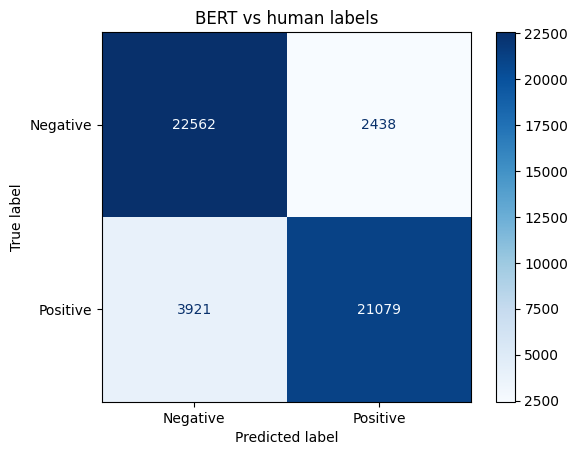

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(reviews["true_label"], reviews["predicted"], target_names=["Negative", "Positive"], digits=3))
ConfusionMatrixDisplay.from_predictions(reviews["true_label"], reviews["predicted"], display_labels=["Negative", "Positive"], cmap="Blues")
plt.title("BERT vs human labels"); plt.show()

## Step 5: Course 2 - pandas (CPU) vs cuDF (GPU)
50,000 rows is small for a GPU, so I copy the data **10 times (500,000 reviews)** to make the speed difference visible. Same code, two engines.

500,000 rows
pandas   11.907 s
cuDF      0.709 s

cuDF is 16.8x faster


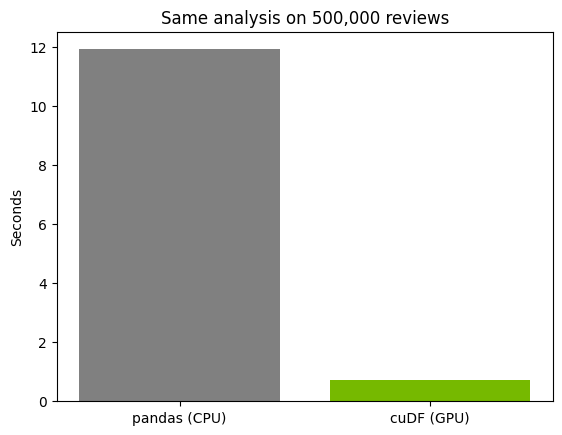

In [8]:
big_pd = pd.concat([reviews[["text", "mood", "confidence"]]] * 10, ignore_index=True)
big_cu = cudf.from_pandas(big_pd)
print(f"{len(big_pd):,} rows")

def analyse(df):
    df = df.copy()
    df["chars"] = df["text"].str.len()                          # string operation
    df["words"] = df["text"].str.count(" ") + 1                 # string operation
    df["mentions_acting"] = df["text"].str.lower().str.contains("acting").astype("float32")
    summary = df.groupby("mood").agg({"chars": "mean", "words": "mean", "confidence": "mean", "mentions_acting": "mean"})
    return summary

def race(label, fn, repeats=3):
    fn()                                                       # warm-up run
    t = time.time()
    for _ in range(repeats):
        out = fn()
    secs = (time.time() - t) / repeats
    print(f"{label:8s} {secs:6.3f} s")
    return out, secs

result_pd, t_pd = race("pandas", lambda: analyse(big_pd))
result_cu, t_cu = race("cuDF", lambda: analyse(big_cu))
print(f"\ncuDF is {t_pd / t_cu:.1f}x faster")

plt.bar(["pandas (CPU)", "cuDF (GPU)"], [t_pd, t_cu], color=["grey", "#76b900"])
plt.ylabel("Seconds"); plt.title(f"Same analysis on {len(big_pd):,} reviews"); plt.show()

## Step 6: What do the results say?
Back to the real 50,000 reviews, now analysed on the GPU with cuDF.

In [9]:
gdf = cudf.from_pandas(reviews[["text", "mood", "confidence", "true_label"]])
gdf["words"] = gdf["text"].str.count(" ") + 1

summary = gdf.groupby("mood").agg({"text": "count", "words": "mean", "confidence": "mean"}).rename(columns={"text": "reviews"})
print(summary)

# Binning: how sure was BERT? (like age bands in the course)
gdf["sureness"] = cudf.cut(gdf["confidence"], bins=[0.5, 0.7, 0.9, 0.99, 1.0], labels=["50-70%", "70-90%", "90-99%", "99%+"])
print("\nHow confident was BERT?")
print(gdf["sureness"].value_counts().sort_index())

# Rate trick: mean of a 0/1 column = percentage
gdf["correct"] = ((gdf["mood"] == "Positive").astype("int8") == gdf["true_label"]).astype("float32")
print("\nAccuracy by confidence band (%):")
print((gdf.groupby("sureness")["correct"].mean() * 100).sort_index().round(1))

          reviews       words  confidence
mood                                     
Negative    26483  238.703432    0.974472
Positive    23517  222.635285    0.972714

How confident was BERT?
sureness
50-70%     1368
70-90%     2383
90-99%     8260
99%+      37989
Name: count, dtype: int64

Accuracy by confidence band (%):
sureness
50-70%    51.7
70-90%    57.7
90-99%    69.6
99%+      94.3
Name: correct, dtype: float64


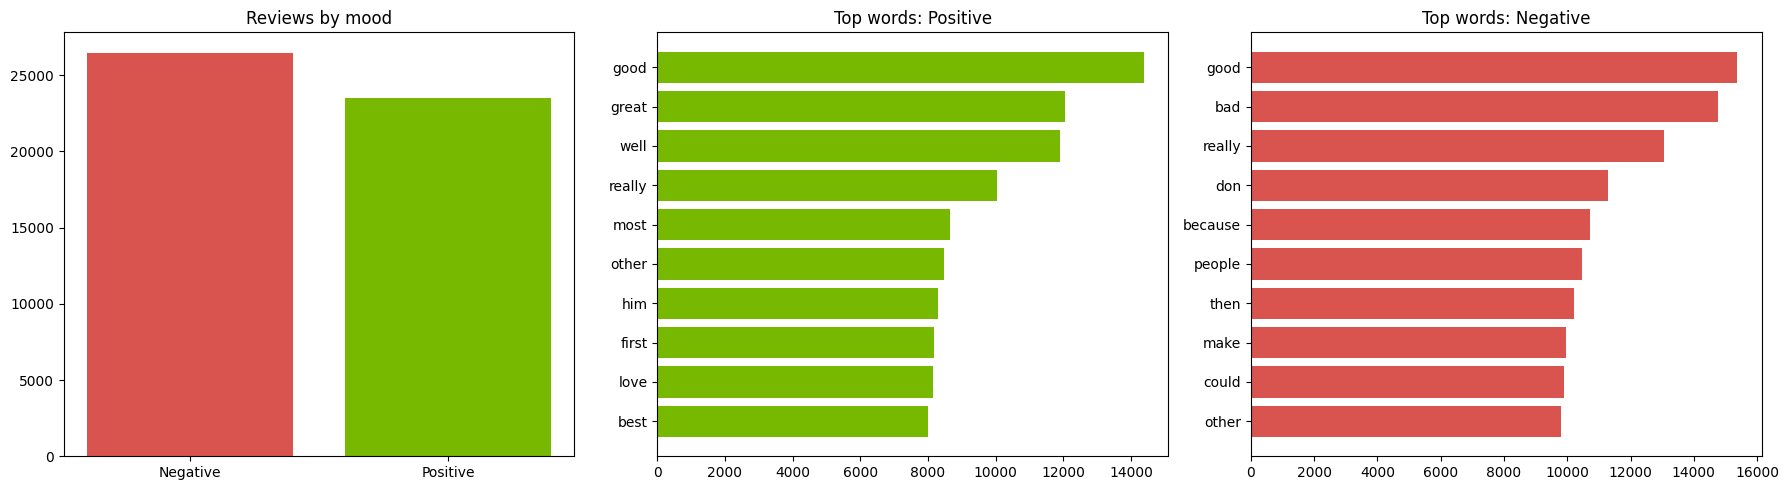

In [10]:
# Most common words in Positive vs Negative reviews (cuDF string tools on the GPU)
stop = ["the","a","and","of","to","is","in","it","i","this","that","was","as","for","with","movie","film","but","on","are",
        "you","not","his","have","he","be","one","its","at","all","by","an","they","from","who","so","like","her","or","just",
        "about","has","if","out","what","some","there","can","more","when","very","she","would","up","my","even","only","no",
        "time","had","which","their","were","see","than","been","do","me","will","we","into","how","also","story","much","get"]

def top_words(mood, n=10):
    words = (gdf.loc[gdf["mood"] == mood, "text"].str.lower()
                .str.replace("<br />", " ", regex=False)
                .str.replace(r"[^a-z ]", " ", regex=True)
                .str.tokenize())
    words = words[~words.isin(stop) & (words.str.len() > 2)]
    return words.value_counts().head(n).to_pandas()

pos_words, neg_words = top_words("Positive"), top_words("Negative")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
counts = summary["reviews"].to_pandas().sort_index()   # Negative, Positive
ax[0].bar(counts.index, counts.values, color=["#d9534f", "#76b900"]); ax[0].set_title("Reviews by mood")
ax[1].barh(pos_words.index[::-1], pos_words.values[::-1], color="#76b900"); ax[1].set_title("Top words: Positive")
ax[2].barh(neg_words.index[::-1], neg_words.values[::-1], color="#d9534f"); ax[2].set_title("Top words: Negative")
plt.tight_layout(); plt.show()

## Step 7: Live demo - try your own review
Change the text and run this cell again.

In [11]:
my_review = "The plot was predictable, but the acting saved the movie and I left the cinema smiling."

p = check_mood([my_review])[0]
mood = "Positive" if p > 0.5 else "Negative"
print(f"Mood: {mood}  |  Confidence: {max(p, 1-p)*100:.1f}%")

Mood: Positive  |  Confidence: 94.3%


## Findings (fill in after running)
- BERT read **50,000** reviews in **__ s** (**__** reviews per second) using FP16 and batching.
- Accuracy against human labels: **__%**, F1: **__**.
- cuDF ran the same analysis **__x faster** than pandas on 500,000 reviews.
- Negative reviews are **longer / shorter** than positive ones (**__** vs **__** words).
- When BERT is 99%+ confident it is right **__%** of the time; at 50-70% confidence only **__%**.

## What I learned
- **Course 1:** text becomes tokens, then numbers; BERT turns them into a score; softmax turns the score into a percentage. Batching and FP16 make inference fast.
- **Course 2:** cuDF uses the same code as pandas but runs on thousands of GPU cores, so the gap grows as the data gets bigger.